# [GIS] 집계구 단위 사회적 고립 위험 지수 프로토타입 — 2026-10-15

**입력**: `master_sgis2024_selected_no_industry_counts.csv` (집계구 × 월, SGIS 2024 + SK 유동인구)
**출력**: `data/processed/isolation_index/`의 집계구별 차원 비율 · z-score · 종합점수 · 백분위 · 5등급 CSV

**방법**: America's Health Rankings "Risk of Social Isolation" 방식 — 차원별 z-score 등가중 평균 → 백분위 5등급.

**잠정 가정** (바꾸려면 아래 설정 셀만 수정)
1. 인구·가구·주택이 0이거나 SK 포인트가 없는 집계구 제외
2. SGIS 결측 = 소량 셀 비공개로 보고 `IMPUTE`(기본 0)로 대치
3. 6개 차원: 1인가구율 · 65세+ 비율 · 50~64세 남성 비율 · 주거취약 거처 비율 · 1989년 이전 주택 비율 · 거주자당 유동인구(역방향)
4. SGIS '총주택'은 주택이외 거처를 포함하지 않으므로 주거취약 분모는 `총주택 + 주택이외 거처`

## 공유 및 실행 안내

- **관련 이슈**: [#13 고립 위험 지수 프로토타입 결과 파일 공유 요청](https://github.com/Team-Hambugi-Lab/bigcontest-social-isolation/issues/13)
- **원본 파일명**: `isolation_index_prototype.ipynb`
- **분석 목적**: 집계구별 위험 신호를 탐색하고 노후주택 포함·제외 등 설정에 따른 민감도를 비교한다.
- **데이터 기간**: SGIS 2024년 통계, SK 통신인구 2025년 7~12월.
- **실행 환경**: 원본 노트북 메타데이터 기준 Python 3.11.11. pandas, numpy, scipy, geopandas, matplotlib 사용. 저장소에서는 `uv sync --extra dev --extra gis`로 관련 의존성을 준비한다.
- **주요 파라미터**: `IMPUTE`, `CLIP_Z`, `WEIGHTS`는 아래 설정 셀에 기재했다.
- **난수 시드**: 난수를 사용하는 절차가 없어 해당 없음.
- **입력 경로**: 저장소 루트를 자동으로 찾고 그 아래 상대경로를 사용한다. 입력 마스터는 `data/processed/master_sgis2024_selected_no_industry_counts.csv`, 경계 파일은 `data/raw/reference_data/강남_집계구경계/`와 `data/raw/reference_data/춘천_집계구경계/`에 배치한다. 경계 파일은 `.shp`와 함께 `.shx`, `.dbf`, `.prj` 등 구성 파일도 같은 폴더에 둔다.
- **공유 범위**: 지수 산식과 기존 분석 출력을 유지하고 파일 경로 및 코드 문자열 읽기 설정을 수정했다. 노후주택 포함·제외 결과 CSV는 Git으로 추적하지 않으며 팀 공유 경로 `data/interim/1차 지역 결과/`에서 별도로 전달한다. 노트북이 새로 생성하는 결과는 로컬 `data/processed/isolation_index/`에 저장한다. 이번 경로 수정 후 다시 계산한 결과는 아니며, 기존 저장 출력도 원본 실행 기록이다. 입력 마스터·경계 파일은 별도로 준비한다.
- **해석 범위**: 지역 집계 자료의 잠정 위험 신호이며 개인의 고립 여부나 확정된 고립 인구를 나타내지 않는다. 상단의 결측 대치·집계구 제외·차원 구성은 프로토타입 가정이다.


In [2]:
from pathlib import Path
import pandas as pd, numpy as np
from scipy.stats import spearmanr
pd.set_option('display.width', 160)

# ===== 설정: 저장소 루트 또는 notebooks/에서 실행 =====
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("저장소 루트 또는 notebooks 폴더에서 노트북을 실행하세요.")

ROOT = find_project_root()
SRC = ROOT / "data/processed/master_sgis2024_selected_no_industry_counts.csv"
BOUNDARY_DIR = ROOT / "data/raw/reference_data"
GANGNAM_SHP = BOUNDARY_DIR / "강남_집계구경계/bnd_oa_11230_2025_2Q.shp"
CHUNCHEON_SHP = BOUNDARY_DIR / "춘천_집계구경계/bnd_oa_32010_2025_2Q.shp"
OUTPUT_DIR = ROOT / "data/processed/isolation_index"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT = OUTPUT_DIR / "isolation_index_prototype.csv"
OUT_NO_OLDHO = OUTPUT_DIR / "isolation_index_no_oldho.csv"

IMPUTE = 0            # SGIS 결측 대치값 (소량 비공개 가정: 0 또는 2)
CLIP_Z = 3            # z-score 절단 (극단값 완화)
WEIGHTS = {           # 차원 가중치 (등가중 = 전부 1, 0이면 제외)
    'p_1in': 1,       # 1인가구 / 총가구
    'p_65': 1,        # 65세+ / 총인구
    'p_m5064': 1,     # 50~64세 남성 / 총인구
    'p_housv': 1,     # (주택이외 거처 + 비주거용 건물내 주택 + 20㎡ 이하) / 총거처
    'p_oldho': 1,     # 1989년 이전 주택 / 총주택
    'flow_pc': 1,     # log(1 + 일평균 유동인구 / 총인구)  ← 낮을수록 위험(역방향)
}
S = 'SGIS2024_'

## 1. 로드 및 유동인구 6개월 평균
SGIS 변수는 월별로 동일하므로 한 달(첫 달)만 남기고, 유동인구만 6개월 평균으로 집계구에 붙인다.

In [3]:
if not SRC.is_file():
    raise FileNotFoundError(
        f"입력 마스터를 {SRC.relative_to(ROOT)}에 배치한 뒤 실행하세요."
    )
df = pd.read_csv(
    SRC, dtype={"TOT_OA_CD": str, "ADM_CD": str, "STD_YM": str}, low_memory=False
)
print('rows', len(df), '| 집계구', df.TOT_OA_CD.nunique(), '| 월', sorted(df.STD_YM.unique()))

wk = ['MON','TUS','WED','THU','FRI','SAT','SUN']
flow_m = pd.DataFrame({
    'flow_day':   df[[f'FLOW_POP_CNT_{d}_sum' for d in wk]].mean(axis=1),       # 일평균 유동 (집계구 내 격자 합)
    'flow_wkday': df[[f'FLOW_POP_CNT_{d}_sum' for d in wk[:5]]].mean(axis=1),
    'flow_wkend': df[[f'FLOW_POP_CNT_{d}_sum' for d in ['SAT','SUN']]].mean(axis=1),
    'flow_5060':  df[[f'{g}_FLOW_POP_CNT_{a}_sum' for g in ['MAN','WMAN'] for a in ['50G','60GU']]].sum(axis=1),
    'TOT_OA_CD': df.TOT_OA_CD,
})
flow = flow_m.groupby('TOT_OA_CD').mean()   # 6개월 평균

first = df.STD_YM.min()
one = df[df.STD_YM == first].set_index('TOT_OA_CD').join(flow)
print('집계구 수', len(one))

rows 10188 | 집계구 1698 | 월 [202507, 202508, 202509, 202510, 202511, 202512]
집계구 수 1698


## 2. 지수 계산 함수

In [4]:
def build(impute=IMPUTE, weights=None, clip=CLIP_Z):
    d = one.copy()
    sg = [c for c in d.columns if c.startswith(S)]
    d[sg] = d[sg].fillna(impute)

    keep = (d[S+'to_in_001'] > 0) & (d[S+'to_ga_001'] > 0) & (d[S+'to_ho_001'] > 0) & (d['HAS_SK_POINTS'] == True)
    d = d[keep].copy()

    pop, hh, ho = d[S+'to_in_001'], d[S+'to_ga_001'], d[S+'to_ho_001']
    age = lambda ids: d[[f'{S}in_age_{i:03d}' for i in ids]].sum(axis=1)
    dwell = ho + d[S+'ho_gb_006']                       # 총거처 = 주택 + 주택이외 거처

    d['p_1in']   = d[S+'ga_sd_005'] / hh
    d['p_65']    = age(range(14, 22)) / pop             # in_age_014~021 = 65세 이상
    d['p_m5064'] = age([41, 42, 43]) / pop              # in_age_041~043 = 50~64세 남자
    d['p_housv'] = (d[S+'ho_gb_006'] + d[S+'ho_gb_005'] + d[S+'ho_ar_001']) / dwell
    d['p_oldho'] = (d[S+'ho_yr_001'] + d[S+'ho_yr_002']) / ho
    d['flow_pc'] = np.log1p(d['flow_day'] / pop)
    d['wkend_ratio'] = d['flow_wkend'] / d['flow_wkday']          # 참고용 (지수 미포함)
    d['p_5060_flow'] = d['flow_5060'] / d['flow_day']             # 참고용 (지수 미포함)

    sign = {'p_1in': 1, 'p_65': 1, 'p_m5064': 1, 'p_housv': 1, 'p_oldho': 1, 'flow_pc': -1}
    w = pd.Series(weights or WEIGHTS)
    z = pd.DataFrame({k: ((d[k] - d[k].mean()) / d[k].std() * sign[k]).clip(-clip, clip) for k in sign})
    d['score']  = (z * w).sum(axis=1) / w.sum()
    d['pctile'] = d['score'].rank(pct=True) * 100
    d['grade']  = pd.cut(d['pctile'], [0, 20, 40, 60, 80, 100], labels=[1, 2, 3, 4, 5]).astype(int)
    for k in sign:
        d['z_' + k] = z[k]
    return d

DIMS = ['p_1in', 'p_65', 'p_m5064', 'p_housv', 'p_oldho', 'flow_pc']
base = build()
print('포함', len(base), '/ 제외', len(one) - len(base))

포함 1649 / 제외 49


## 3. 결과

In [5]:
print('[차원 기술통계]')
display(base[DIMS].describe().T[['mean', '50%', 'min', 'max']].round(3))
print('[차원 간 Spearman]')
display(base[DIMS].corr('spearman').round(2))

[차원 기술통계]


,mean,50%,min,max
p_1in,0.305,0.228,0.000,0.942
p_65,0.177,0.157,0.000,0.652
p_m5064,0.114,0.115,0.000,0.239
p_housv,0.054,0.000,0.000,1.000
p_oldho,0.183,0.000,0.000,1.000
flow_pc,1.486,1.101,0.077,6.205


[차원 간 Spearman]


,p_1in,p_65,p_m5064,p_housv,p_oldho,flow_pc
p_1in,1.00,0.20,-0.27,0.58,0.13,0.42
p_65,0.20,1.00,0.29,0.04,0.38,0.12
p_m5064,-0.27,0.29,1.00,-0.15,0.10,-0.04
p_housv,0.58,0.04,-0.15,1.00,0.24,0.57
p_oldho,0.13,0.38,0.10,0.24,1.00,0.29
flow_pc,0.42,0.12,-0.04,0.57,0.29,1.00


In [6]:
print('[지역 × 등급: 집계구 수]')
display(pd.crosstab(base.REGION, base.grade))
print('[지역 × 등급: 1인가구 수]')
display(pd.crosstab(base.REGION, base.grade, values=base[S+'ga_sd_005'], aggfunc='sum').astype(int))

g5 = base[base.grade == 5]
tot = base[S+'ga_sd_005'].sum()
print(f"5등급 집계구 {len(g5)}개 | 1인가구 {int(g5[S+'ga_sd_005'].sum()):,} / {int(tot):,} ({g5[S+'ga_sd_005'].sum()/tot:.1%}) | 총인구 {int(g5[S+'to_in_001'].sum()):,}")

[지역 × 등급: 집계구 수]


grade,1,2,3,4,5
REGION,,,,,
강남구,236,238,229,203,149
춘천시,93,92,101,127,181


[지역 × 등급: 1인가구 수]


grade,1,2,3,4,5
REGION,,,,,
강남구,9097,14201,21746,19715,10597
춘천시,2774,4582,6416,13306,23374


5등급 집계구 330개 | 1인가구 33,971 / 125,808 (27.0%) | 총인구 160,233


In [7]:
print('[상위 15 집계구]')
display(base.sort_values('score', ascending=False).head(15)[['REGION', 'ADM_CD', S+'to_in_001', S+'ga_sd_005'] + DIMS + ['score', 'pctile']].round(3))

[상위 15 집계구]


,REGION,ADM_CD,SGIS2024_to_in_001,SGIS2024_ga_sd_005,p_1in,p_65,p_m5064,p_housv,p_oldho,flow_pc,score,pctile
TOT_OA_CD,,,,,,,,,,,,
32010620011101,춘천시,32010620,677.0,442.0,0.810,0.536,0.194,0.000,0.000,0.607,1.291,100.000
32010390010002,춘천시,32010390,511.0,152.0,0.478,0.544,0.205,0.063,0.415,1.818,1.203,99.939
32010640020102,춘천시,32010640,375.0,207.0,0.734,0.477,0.184,0.000,0.000,0.487,1.185,99.879
32010600010008,춘천시,32010600,351.0,169.0,0.713,0.251,0.165,0.027,0.945,0.782,1.151,99.818
32010570020001,춘천시,32010570,348.0,102.0,0.520,0.305,0.239,0.133,0.815,2.431,1.133,99.757
32010370010002,춘천시,32010370,470.0,136.0,0.515,0.440,0.228,0.063,0.219,1.482,1.106,99.697
32010570040001,춘천시,32010570,396.0,110.0,0.502,0.356,0.189,0.000,0.589,0.980,1.074,99.636
32010530010006,춘천시,32010530,399.0,141.0,0.624,0.291,0.135,0.470,0.413,2.176,1.046,99.576
32010570040002,춘천시,32010570,392.0,231.0,0.819,0.163,0.115,0.901,0.630,1.734,1.040,99.515


## 4. 민감도
기본안과 대안 설정의 순위 상관(Spearman)과 5등급 일치율.

In [8]:
def agree(a, b):
    j = a[['score', 'grade']].join(b[['score', 'grade']], rsuffix='_b')
    rho = spearmanr(j.score, j.score_b).correlation
    top = ((j.grade == 5) & (j.grade_b == 5)).sum() / (j.grade == 5).sum()
    return round(rho, 3), f'{top:.0%}'

W = WEIGHTS
alts = {
    '결측 2 대치':                build(impute=2),
    '유동인구 제외':              build(weights={**W, 'flow_pc': 0}),
    '주거 2차원 제외':            build(weights={**W, 'p_housv': 0, 'p_oldho': 0}),
    '인구 3차원만':               build(weights={'p_1in': 1, 'p_65': 1, 'p_m5064': 1, 'p_housv': 0, 'p_oldho': 0, 'flow_pc': 0}),
    '가중(독거2·고령1.5·남성1.5)': build(weights={'p_1in': 2, 'p_65': 1.5, 'p_m5064': 1.5, 'p_housv': 1, 'p_oldho': 0.5, 'flow_pc': 0.5}),
}
pd.DataFrame({k: agree(base, v) for k, v in alts.items()}, index=['Spearman', '5등급 일치']).T

,Spearman,5등급 일치
결측 2 대치,0.981,93%
유동인구 제외,0.899,78%
주거 2차원 제외,0.793,61%
인구 3차원만,0.784,64%
가중(독거2·고령1.5·남성1.5),0.875,70%


## 5. 저장

In [ ]:
cols = ['REGION', 'ADM_CD', 'AREA_M2', S+'to_in_001', S+'to_ga_001', S+'ga_sd_005'] + DIMS + ['wkend_ratio', 'p_5060_flow'] + ['z_' + k for k in DIMS] + ['score', 'pctile', 'grade']
base[cols].to_csv(OUT, encoding='utf-8-sig')
print('saved →', OUT.relative_to(ROOT), base[cols].shape)

## 메모 (프로토타입 실행 시 관찰)
- 결측 대치값(0 vs 2)은 결과를 거의 바꾸지 않음 (Spearman 0.98). 차원 구성·가중치가 훨씬 중요.
- `p_1in`과 `p_m5064`가 음의 상관(강남 1인가구는 청년) → 중장년 독거를 잡으려면 SGIS '1인가구 연령별' 교차표 필요.
- `flow_pc`가 `p_1in`과 양의 상관(+0.42) → 1인가구 밀집지(오피스텔·상업지)는 유동이 많음. "유동 적음 = 고립" 가정이 독거 차원을 상쇄하므로 유동 변수는 재정의(주말/평일비, 야간 체류)하거나 보조 지표로 분리 검토.


In [10]:
# 차원별 기여도 (feature importance 대용)
Z = z_cols = ['z_' + k for k in DIMS]
z = base[Z].copy(); z.columns = DIMS
g5 = base.grade == 5
imp = pd.DataFrame(index=DIMS)
imp['score 상관'] = [spearmanr(z[k], base.score).correlation for k in DIMS]
for k in DIMS:
    s = z.drop(columns=k).mean(axis=1)
    imp.loc[k, '제거 시 5등급 유지율'] = ((s.rank(pct=True) > 0.8) & g5).sum() / g5.sum()
imp['5등급 평균 기여'] = (z[g5] / len(DIMS)).mean()
zz = (z - z.mean()) / z.std()
_, sv, vt = np.linalg.svd(zz.values, full_matrices=False)
imp['PCA1 적재'] = vt[0] * np.sign(vt[0][0])
print('PCA1 설명분산', round(sv[0]**2 / (sv**2).sum(), 3))
imp.round(3)

PCA1 설명분산 0.363


,score 상관,제거 시 5등급 유지율,5등급 평균 기여,PCA1 적재
p_1in,0.365,0.794,0.059,0.552
p_65,0.683,0.748,0.187,-0.014
p_m5064,0.410,0.800,0.095,-0.276
p_housv,0.249,0.888,0.010,0.579
p_oldho,0.607,0.642,0.178,-0.077
flow_pc,-0.049,0.776,-0.001,-0.527


# 1. 노후주택 빼고 돌리기

In [11]:
# 노후주택 제외
W2 = {**WEIGHTS, 'p_oldho': 0}
alt = build(weights=W2)

# 기존(base)과 비교
print(pd.DataFrame({'기존': base.grade.value_counts().sort_index(),
                    '노후주택 제외': alt.grade.value_counts().sort_index()}))
print(pd.crosstab(alt.REGION, alt.grade))
print('Spearman', spearmanr(base.score, alt.score).correlation.round(3),
      '| 5등급 유지', ((base.grade == 5) & (alt.grade == 5)).sum() / (base.grade == 5).sum())

# 등급이 바뀐 집계구 (어디가 내려가고 올라갔나)
chg = base[['REGION', 'grade']].join(alt[['grade']], rsuffix='_new')
print(pd.crosstab([chg.REGION, chg.grade], chg.grade_new))

alt[cols].to_csv(OUT_NO_OLDHO, encoding='utf-8-sig')

        기존  노후주택 제외
grade              
1      329      329
2      330      330
3      330      330
4      330      330
5      330      330
grade     1    2    3    4    5
REGION                         
강남구     241  253  255  201  105
춘천시      88   77   75  129  225
Spearman 0.875 | 5등급 유지 0.6424242424242425
grade_new       1    2    3   4    5
REGION grade                        
강남구    1      214   22    0   0    0
       2        6  169   63   0    0
       3       10   11  121  87    0
       4       11   51   13  72   56
       5        0    0   58  42   49
춘천시    1       86    7    0   0    0
       2        0   60   32   0    0
       3        2    6   40  53    0
       4        0    4    2  59   62
       5        0    0    1  17  163


EPSG:5179 EPSG:5179
조인 성공 1649 / 1698


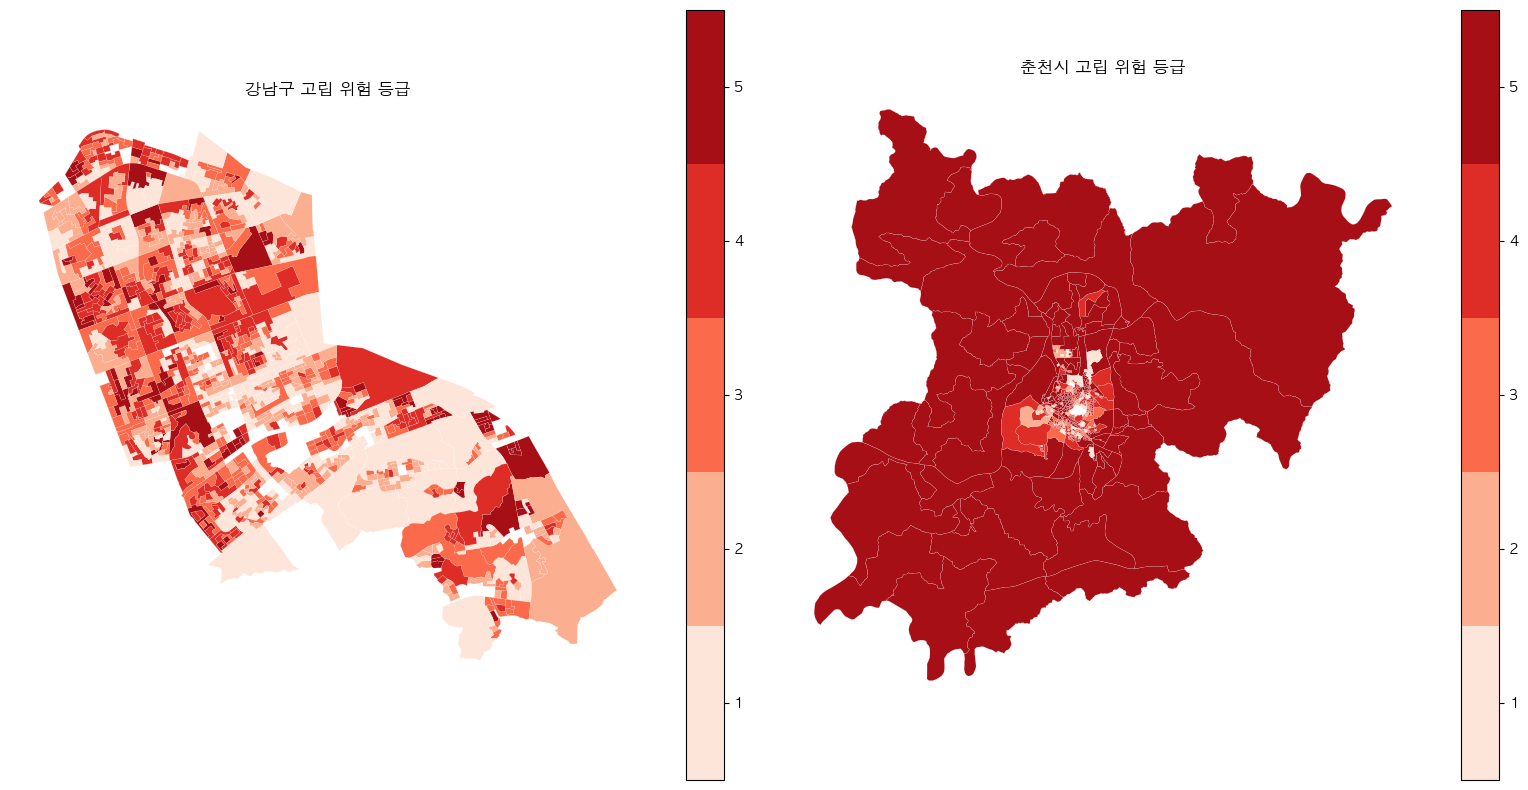

In [14]:
import geopandas as gpd, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

plt.rcParams['font.family'] = 'AppleGothic'

g1 = gpd.read_file(GANGNAM_SHP)
g2 = gpd.read_file(CHUNCHEON_SHP)
print(g1.crs, g2.crs)                       # 다르면 아래 한 줄로 통일
g2 = g2.to_crs(g1.crs)
gdf = pd.concat([g1, g2], ignore_index=True)
gdf['TOT_OA_CD'] = gdf['TOT_OA_CD'].astype(str)

res = alt[['REGION', 'grade', 'score']].copy()   # 또는 base
res.index = res.index.astype(str)
m = gdf.merge(res, left_on='TOT_OA_CD', right_index=True, how='left')
print('조인 성공', m.grade.notna().sum(), '/', len(m))   # 1649 근처여야 정상

cmap = ListedColormap(['#fee5d9', '#fcae91', '#fb6a4a', '#de2d26', '#a50f15'])
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, reg in zip(axes, ['강남구', '춘천시']):
    sub = m[m.REGION == reg]
    sub.plot(column='grade', cmap=cmap, vmin=0.5, vmax=5.5, edgecolor='white',
             linewidth=0.1, ax=ax, legend=True,
             missing_kwds={'color': 'lightgrey', 'label': '제외'})
    ax.set_title(f'{reg} 고립 위험 등급'); ax.set_axis_off()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'grade_map.png', dpi=150)

조인 성공 1649 / 1698


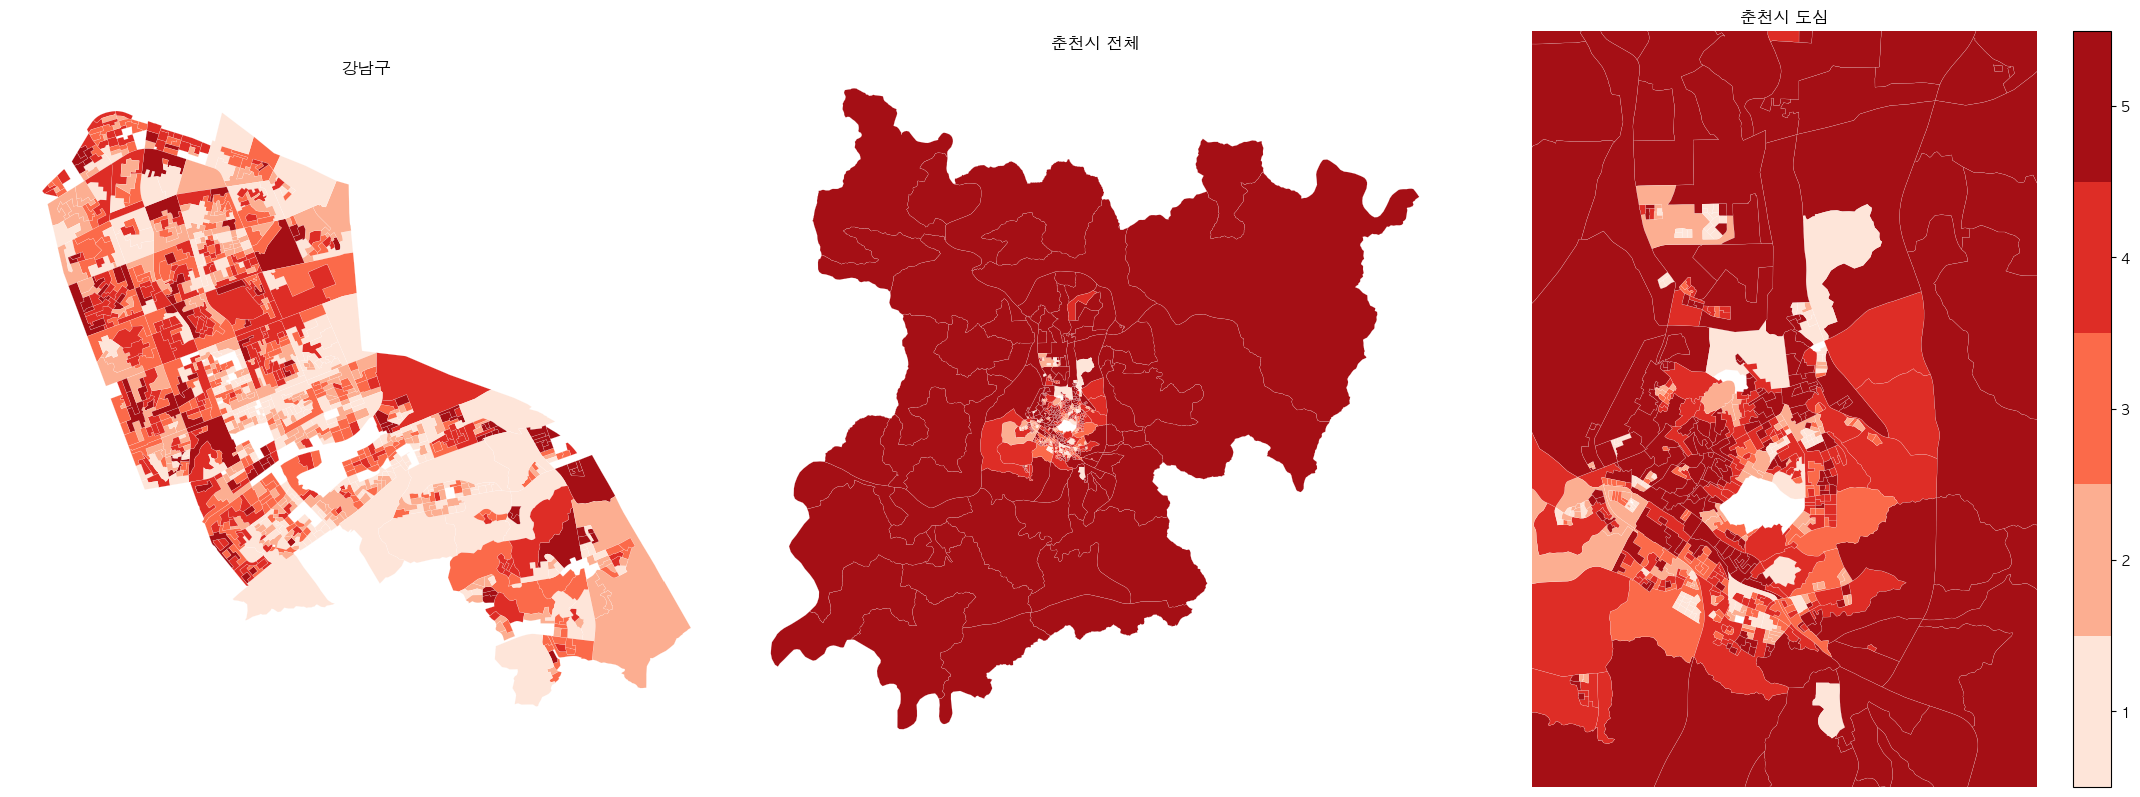

In [15]:
import geopandas as gpd, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

plt.rcParams['font.family'] = 'AppleGothic'

g1 = gpd.read_file(GANGNAM_SHP)
g2 = gpd.read_file(CHUNCHEON_SHP).to_crs(g1.crs)
gdf = pd.concat([g1, g2], ignore_index=True)
gdf['TOT_OA_CD'] = gdf['TOT_OA_CD'].astype(str)

res = alt[['REGION', 'grade', 'score']].copy()   # 또는 base
res.index = res.index.astype(str)
m = gdf.merge(res, left_on='TOT_OA_CD', right_index=True, how='left')
print('조인 성공', m.grade.notna().sum(), '/', len(m))

cmap = ListedColormap(['#fee5d9', '#fcae91', '#fb6a4a', '#de2d26', '#a50f15'])

def draw(sub, ax, title, bbox=None, legend=False):
    sub.plot(column='grade', cmap=cmap, vmin=0.5, vmax=5.5,
             edgecolor='white', linewidth=0.1, ax=ax, legend=legend,
             missing_kwds={'color': 'lightgrey', 'label': '제외'})
    if bbox is not None:
        xmin, ymin, xmax, ymax = bbox
        ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_title(title); ax.set_axis_off()

gn = m[m.REGION == '강남구']
cc = m[m.REGION == '춘천시']

# 춘천 도심 범위: 면적 0.5km² 미만 집계구(동 지역)의 외곽 경계 + 5% 여백
urban = cc[cc.geometry.area < 5e5]
xmin, ymin, xmax, ymax = urban.total_bounds
mx, my = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
cc_bbox = (xmin - mx, ymin - my, xmax + mx, ymax + my)

fig, axes = plt.subplots(1, 3, figsize=(22, 8))
draw(gn, axes[0], '강남구')
draw(cc, axes[1], '춘천시 전체')
draw(cc, axes[2], '춘천시 도심', bbox=cc_bbox, legend=True)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'grade_map.png', dpi=150)

In [16]:
out = m[['TOT_OA_CD', 'ADM_CD', 'REGION', 'grade', 'score', 'geometry']].copy()
out = out.rename(columns={'REGION': 'region'})   # 전부 10자 이내
out['grade'] = out['grade'].astype('Int64')      # NaN 유지하면서 정수

out.to_file(OUTPUT_DIR / 'isolation_grade.shp', encoding='utf-8')

In [17]:
full = m.merge(alt[DIMS + ['pctile']].set_index(alt.index.astype(str)),
               left_on='TOT_OA_CD', right_index=True, how='left')
full.to_file(OUTPUT_DIR / 'isolation_grade.gpkg', layer='grade', driver='GPKG')